# Lecture 27 notebook: the baseline trend portfolio

This notebook replays Lecture 27. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process. The data are free and the same as Lecture 26's: the daily prices of Lecture 25's ETFs from Yahoo Finance, the 3-month Treasury bill rate from FRED, and Lecture 26's 36 daily trend streams per market (built by Lecture 26's notebook or here if missing). The futures checks of §2.4, §5 and §6 also use the capstone futures of Lecture 11 (local, not committed) and two Treasury funds and the S&P 500 from Yahoo, saved once.

By default the notebook builds the baseline's daily returns if they are not there yet, redraws every figure of the lecture as `figures/nb_*.png` from the shipped results, and checks the lecture's mechanics by hand: the baseline rebuilt for one year, the equal-risk-contribution weights, the number of independent bets, the part-time statistics and the take-profit rule. `RUN_ALL` also reruns every analysis (about an hour, one script at a time) and compares the key numbers with the shipped ones. Recomputed results never overwrite the shipped ones.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings and data | |
| 1 | The key chart; the baseline rebuilt for one year | §1 |
| 2 | Speeds inside a market: overlap by speed ratio, equal risk contributions by hand, the blends, part-time streams, timing | §2 |
| 3 | Markets and classes: equal capital, groups | §3 |
| 4 | The total: volatility target and constant leverage, daily rescaling | §4 |
| 5 | Taking profits, with the rule by hand | §5 |
| 6 | Crises and today's portfolio | §6 |
| 7 | Shipped against recomputed; a test of your own | |

## 0. Settings and data

In [1]:
import json, os, shutil, subprocess, sys, time
from itertools import combinations
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l27 as M
L26, L25 = M.L26, M.L25
RUN_ALL = False                                                            # True: also rerun every analysis (about an hour)

SHIPPED = HERE / "results"; WORK = L25.DATA / "l27_results"               # recomputed results go to WORK, never over the shipped ones
if not WORK.exists(): shutil.copytree(SHIPPED, WORK)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
print("data:", L25.DATA, "| streams:", L26.OUT / "streams", "| daily results:", M.OUT, "| shipped results:", SHIPPED, "| recomputed results:", WORK)


def run(script, *args, show=False):
    "Run a script of this lecture (or of Lectures 25-26) in a fresh process; figures as nb_*, results to WORK."
    t0 = time.time(); path = next(p for p in (SCRIPTS / script, M.REPO / "lectures" / "26-trend-speeds-by-asset-class" / "scripts" / script,
                                              M.REPO / "lectures" / "25-choosing-the-markets" / "scripts" / script) if p.exists())
    env = {**os.environ, "PORTFOLIO_DATA": str(L25.DATA), "L27_RESULTS": str(WORK), "L27_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, str(path), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def result(name, where=None):
    return json.loads(((where or WORK) / name).read_text(encoding="utf-8"))

data: C:\Users\maxgn\New Trading Models\data\raw\portfolio | streams: C:\Users\maxgn\New Trading Models\data\raw\portfolio\l26\streams | daily results: C:\Users\maxgn\New Trading Models\data\raw\portfolio\l27 | shipped results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\lectures\27-the-baseline-trend-portfolio\results | recomputed results: C:\Users\maxgn\New Trading Models\data\raw\portfolio\l27_results


**The data.** Lecture 25's prices, the bill rate and Lecture 26's streams are fetched or built if missing. The baseline's daily out-of-sample returns, with its rivals, are built once by `l27.py` (about ten minutes).

In [2]:
if not L25.RAW.exists(): run("l25_fetch.py", show=True)
if not L26.RATE.exists(): run("l26_fetch_rate.py", show=True)
if len(list((L26.OUT / "streams").glob("*.parquet"))) < 100: run("l26_streams.py", show=True)
if not (M.OUT / "l27_daily.parquet").exists(): run("l27.py")
close, high, low, dv, rf = L26.load_daily(); D = pd.read_parquet(M.OUT / "l27_daily.parquet")
print(f"{close.shape[1]} ETFs to {close.index.max().date()}; baseline daily returns {D.index.min().date()} to {D.index.max().date()}, Sharpe ratio {L26.sharpe(D['rule']):.3f}")

116 ETFs to 2026-11-12; baseline daily returns 2013-01-02 to 2026-11-12, Sharpe ratio 0.486


**Running everything.** With `RUN_ALL` the cell below reruns every analysis of the lecture, one at a time: the baseline and its rivals, the tests, the speed blends, timing, scaling the total, the futures test, crises, take-profit and the stress test. The futures scripts need the capstone futures of Lecture 11 (`data/interim/l11_series99.pkl`); without them they are skipped.

In [3]:
if RUN_ALL:
    for s in ("l27.py", "l27_tests.py", "l27_speeds.py", "l27_timing.py", "l27_leverage.py", "l27_states.py"): run(s)
    if (M.REPO / "data" / "interim" / "l11_series99.pkl").exists():
        for s in ("l27_futures_test.py", "l27_crisis.py", "l27_takeprofit.py", "l27_stress.py"): run(s)
    else: print("capstone futures not found: futures checks skipped")
    D = pd.read_parquet(M.OUT / "l27_daily.parquet")

## 1. The key chart

Left: the correlation of two streams in the same market against the ratio of their speeds. Right: each class's share of capital and of risk.

l27_key_chart.py : 12 s
ewma {Interval(1.0, 1.5, closed='right'): 0.93, Interval(1.5, 2.5, closed='right'): 0.84, Interval(2.5, 5.0, closed='right'): 0.65, Interval(5.0, 10.0, closed='right'): 0.43, Interval(10.0, 60.0, closed='right'): 0.22}
breakout {Interval(1.0, 1.5, closed='right'): 0.9, Interval(1.5, 2.5, closed='right'): 0.82, Interval(2.5, 5.0, closed='right'): 0.63, Interval(5.0, 10.0, closed='right'): 0.44, Interval(10.0, 60.0, closed='right'): 0.25}
return {Interval(1.0, 1.5, closed='right'): 0.84, Interval(1.5, 2.5, closed='right'): 0.74, Interval(2.5, 5.0, closed='right'): 0.58, Interval(5.0, 10.0, closed='right'): 0.44, Interval(10.0, 60.0, closed='right'): 0.28}
same speed, different rules 0.88
{'Equity': (np.float64(0.096), np.float64(0.228)), 'Rates': (np.float64(0.467), np.float64(0.185)), 'Credit': (np.float64(0.194), np.float64(0.22)), 'Commodities': (np.float64(0.075), np.float64(0.183)), 'FX': (np.float64(0.168), np.float64(0.184))}



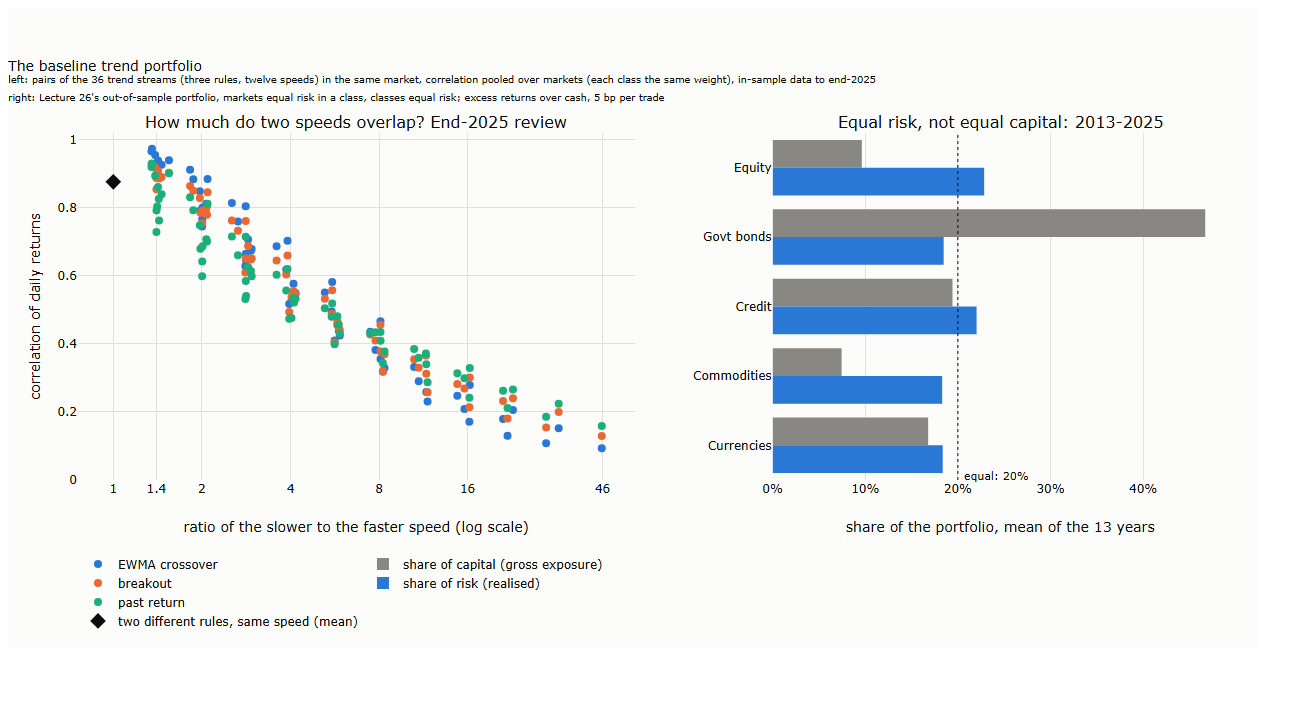

In [4]:
run("l27_key_chart.py", show=True)
pictures("27_key")

### 1.1 The baseline rebuilt for one year

The baseline in one sentence (§1): speeds at equal weight in each market, markets at equal risk in each class, classes at equal risk, the total scaled to 10% on the past three years. Rebuilt here for 2026, chosen at the end-2025 review, from Lecture 26's net stream returns, against the stored daily returns.

In [5]:
NET = {}
def net(t):
    if t not in NET: NET[t] = L26.net(pd.read_parquet(L26.OUT / "streams" / f"{t}.parquet")[L26.START:])
    return NET[t]
y = 2025; held = [k for k, v in M.SEL[str(y)]["weights"]["one_set"].items() if v >= 0.2]; uni = M.UNI[str(y)]["sc_div"]
hist, nxt = slice(f"{y - 2}-01-01", f"{y}-12-31"), slice(f"{y + 1}-01-01", f"{y + 1}-12-31"); day = M.TARGET / np.sqrt(252)
R = pd.DataFrame({t: net(t)[held].mean(axis=1) for k in uni for t in uni[k]})          # step 1: speeds at equal weight
a = 1 / R.loc[hist].std()                                                              # step 2: markets at equal risk
cls = {k: R[m].mul(a[m]).mean(axis=1) for k, m in uni.items()}
cls = {k: v * day / v.loc[hist].std() for k, v in cls.items()}                        # step 3: classes at equal risk
U = pd.DataFrame(cls).mean(axis=1); base = (U * day / U.loc[hist].std()).loc[nxt]       # step 4: total at 10%
print(f"{len(held)} streams, {sum(map(len, uni.values()))} markets in {len(uni)} classes; largest daily difference from the stored baseline: {(base - D['rule'].reindex(base.index)).abs().max():.1e}")

20 streams, 20 markets in 5 classes; largest daily difference from the stored baseline: 2.5e-09


## 2. Speeds inside a market

### 2.1 Overlap by speed ratio

The pooled correlation of the 36 streams at the end-2025 review (each class the same weight), averaged over pairs of the same rule by ratio of speeds, and over different rules at the same speed.

In [6]:
S = result("speeds.json"); Cr = pd.DataFrame(S["reviews"]["2025"]["corr"])
pairs = [(int(b.split("_")[1]) / int(a.split("_")[1]), a.split("_")[0], Cr.loc[a, b]) for r in L26.RULES for a, b in combinations([f"{r}_{h}" for h in L26.SPEEDS], 2)]
P = pd.DataFrame(pairs, columns=["ratio", "rule", "corr"]); P["ratio band"] = pd.cut(P.ratio, [1, 1.5, 2.5, 5, 10, 60], labels=["1.4", "2", "3-4", "6-8", "11-46"])
display(P.pivot_table(index="rule", columns="ratio band", values="corr", aggfunc="mean", observed=True).round(2))
same = [Cr.loc[f"{a}_{h}", f"{b}_{h}"] for h in (61, 89, 127, 179, 251, 359) for a, b in combinations(L26.RULES, 2)]
print(f"different rules at the same speed (61-359 days): {np.mean(same):.2f}")

ratio band,1.4,2,3-4,6-8,11-46
rule,,,,,
breakout,0.90,0.82,0.63,0.44,0.25
ewma,0.93,0.84,0.65,0.43,0.22
return,0.84,0.74,0.58,0.44,0.28


different rules at the same speed (61-359 days): 0.88


### 2.2 Equal risk contributions and independent bets, by hand

For the held streams at the end-2025 review: the weights of `l27_speeds.erc`, then each stream's risk contribution $`w_i (Cw)_i`$ computed by hand (they should be equal), and the number of independent bets $`(\sum_i w_i)^2 / w^\top C w`$ for equal weights and for equal risk contributions.

In [7]:
import l27_speeds as SP
held = S["reviews"]["2025"]["held"]; Ch = Cr.loc[held, held].to_numpy()
w, _ = SP.erc(Ch, np.ones(len(held))); rc = w * (Ch @ w); rc = rc / rc.sum(); eq = np.ones(len(held)) / len(held)
print(f"weights {w.min():.3f} to {w.max():.3f} (equal: {1 / len(held):.3f}); risk contributions {rc.min():.4f} to {rc.max():.4f} (equal: {1 / len(held):.4f})")
print(f"stored weights match: {np.allclose(w, pd.Series(S['reviews']['2025']['weights']['correlation'])[held].to_numpy(), atol=1e-3)}")
print(f"independent bets: equal weights {eq.sum() ** 2 / (eq @ Ch @ eq):.2f}, equal risk contributions {w.sum() ** 2 / (w @ Ch @ w):.2f}; average pairwise correlation {Ch[np.triu_indices(len(held), 1)].mean():.2f}")

weights 0.045 to 0.058 (equal: 0.050); risk contributions 0.0500 to 0.0500 (equal: 0.0500)
stored weights match: True
independent bets: equal weights 1.39, equal risk contributions 1.41; average pairwise correlation 0.70


### 2.3 The blends out of sample

Sharpe ratio after costs 2013-2026 for each blend, and the streams maximum Sharpe ratio picked at three reviews.

In [8]:
display(pd.Series(S["oos"]).rename("Sharpe ratio, 2013-2026").round(3).to_frame())
for y in ("2012", "2018", "2025"):
    ms = {k: round(v, 2) for k, v in S["reviews"][y]["weights"]["max_sharpe"].items() if v > 0.01}
    print(f"{y}: maximum Sharpe ratio holds {len(ms)} of {len(S['reviews'][y]['held'])} streams: {ms}")

,"Sharpe ratio, 2013-2026"
equal,0.486
correlation,0.482
max_sharpe,0.455
cost_0.2,0.483
cost_0.3,0.482
cost_0.5,0.482


2012: maximum Sharpe ratio holds 5 of 19 streams: {'ewma_89': 0.22, 'ewma_179': 0.5, 'ewma_359': 0.07, 'breakout_359': 0.1, 'return_61': 0.1}
2018: maximum Sharpe ratio holds 3 of 17 streams: {'ewma_89': 0.55, 'breakout_61': 0.06, 'breakout_127': 0.39}
2025: maximum Sharpe ratio holds 5 of 20 streams: {'ewma_89': 0.58, 'breakout_61': 0.08, 'breakout_359': 0.15, 'return_179': 0.03, 'return_359': 0.16}


### 2.4 Streams that are not always in the market

The held breakout streams of Lecture 25's end-2025 markets: the share of days with a signal, and the Sharpe ratio after costs over all days and on the days with a signal (the signal of the day before, which sets the position held), 2007-2026, median over markets; then Lecture 7's link, Sharpe while active times the square root of the share of time active.

In [9]:
names = sorted({t for m in M.UNI["2025"]["sc_div"].values() for t in m}); bk = [k for k in M.SEL["2025"]["weights"]["one_set"] if k.startswith("breakout") and M.SEL["2025"]["weights"]["one_set"][k] >= 0.2]
rows = []
for t in names:
    c = close[t].dropna(); x, xh, xl = L26.excess(c, high[t].reindex(c.index), low[t].reindex(c.index), rf); r = net(t)
    for k in bk:
        s = L26.signals(x.to_frame("x"), xh.to_frame("x"), xl.to_frame("x"), int(k.split("_")[1]))["breakout"]["x"].shift(1)
        rr = r[k].dropna(); on = s.reindex(rr.index).fillna(0) != 0
        rows.append(dict(market=t, stream=k, share=on.mean(), all_days=L26.sharpe(rr), active=L26.sharpe(rr[on])))
PT = pd.DataFrame(rows); med = PT[["share", "all_days", "active"]].median()
display(PT.groupby("stream")[["share", "all_days", "active"]].median().round(2))
print(f"median: in the market {med.share:.0%} of days; Sharpe {med.all_days:.2f} on all days, {med.active:.2f} while active; {med.active:.2f} x sqrt({med.share:.2f}) = {med.active * np.sqrt(med.share):.2f}")

,share,all_days,active
stream,,,
breakout_127,0.73,0.24,0.28
breakout_179,0.71,0.20,0.25
breakout_251,0.71,0.20,0.24
breakout_359,0.70,0.17,0.26
breakout_61,0.70,0.20,0.27
breakout_89,0.71,0.21,0.22


median: in the market 71% of days; Sharpe 0.20 on all days, 0.26 while active; 0.26 x sqrt(0.71) = 0.22


### 2.5 Timing the speeds

Momentum and reversal tilts within the held set, against equal weights (90% bands from a block bootstrap over months).

In [10]:
T = result("timing.json")
pd.DataFrame({k: {"Sharpe": v["sharpe"], "difference": v["diff"], "band 5%": (v["ci90"] or [np.nan])[0], "band 95%": (v["ci90"] or [np.nan, np.nan])[1]} for k, v in T.items()}).T.round(3)

,Sharpe,difference,band 5%,band 95%
equal,0.486,0.000,NaN,NaN
momentum_3m_k0.5,0.430,-0.056,-0.078,-0.033
momentum_3m_k1.0,0.374,-0.112,-0.159,-0.063
momentum_6m_k0.5,0.434,-0.052,-0.072,-0.030
momentum_6m_k1.0,0.382,-0.104,-0.145,-0.063
reversal_3m_k0.5,0.508,0.022,-0.003,0.048
reversal_3m_k1.0,0.529,0.042,-0.008,0.094
reversal_6m_k0.5,0.512,0.026,0.001,0.048
reversal_6m_k1.0,0.535,0.049,0.003,0.096


## 3. Markets and classes

Equal risk against equal capital inside the classes, and the classes against groups found in the data, from the daily returns; then the tests.

In [11]:
dd = lambda x: ((1 + x).cumprod() / (1 + x).cumprod().cummax() - 1).min()
gross = D.gross_U * D.ctot
display(pd.DataFrame({"equal risk (baseline)": {"Sharpe": L26.sharpe(D.rule), "volatility": D.rule.std() * np.sqrt(252), "worst drawdown": dd(D.rule), "gross, median": gross.median()},
                      "equal capital": {"Sharpe": L26.sharpe(D.equal_capital), "volatility": D.equal_capital.std() * np.sqrt(252), "worst drawdown": dd(D.equal_capital), "gross, median": D.gross_eqcap.median()},
                      "groups, Ward": {"Sharpe": L26.sharpe(D.ward), "volatility": D.ward.std() * np.sqrt(252), "worst drawdown": dd(D.ward)},
                      "groups, average linkage": {"Sharpe": L26.sharpe(D.groups), "volatility": D.groups.std() * np.sqrt(252), "worst drawdown": dd(D.groups)}}).T.round(3))
print(f"correlation of daily returns, equal capital with the baseline: {D.rule.corr(D.equal_capital):.3f}")
X = result("tests.json"); display(pd.DataFrame({k: {"difference": v["diff"], "band 5%": v["ci90"][0], "band 95%": v["ci90"][1]} for k, v in X["tests"].items()}).T.round(3))
print("passes Benjamini-Hochberg:", {k: v for k, v in X["bh"].items()})

,Sharpe,volatility,worst drawdown,"gross, median"
equal risk (baseline),0.486,0.107,-0.222,3.380
equal capital,0.442,0.105,-0.244,2.165
"groups, Ward",0.522,0.108,-0.210,NaN
"groups, average linkage",0.532,0.109,-0.248,NaN


correlation of daily returns, equal capital with the baseline: 0.981


,difference,band 5%,band 95%
aware_sharpe,-0.019,-0.140,0.103
aware_drawdown,-0.056,-0.062,0.043
aware_risk_spread,0.087,0.027,0.137
ward_sharpe,0.036,-0.120,0.183
ward_drawdown,0.012,-0.022,0.113
ward_risk_spread,0.035,-0.007,0.075
groups_sharpe,0.046,-0.152,0.249
groups_drawdown,-0.026,-0.041,0.134
groups_risk_spread,0.050,-0.017,0.122


passes Benjamini-Hochberg: {'aware_risk_spread': False, 'ward_risk_spread': False, 'ward_drawdown': False, 'ward_sharpe': False, 'aware_sharpe': False, 'aware_drawdown': False}


Each class's share of capital and of risk (its contribution to the variance of the total), mean of the years.

In [12]:
L = result("leverage.json"); sh = L["class_shares"]
pd.DataFrame({k: {"capital": np.mean([sh[y][k]["capital"] for y in sh]), "risk": np.mean([sh[y][k]["risk"] for y in sh])} for k in L26.CLASSES}).T.round(3)

,capital,risk
Equity,0.096,0.228
Rates,0.467,0.185
Credit,0.194,0.220
Commodities,0.075,0.183
FX,0.168,0.184


## 4. The total

Volatility target against constant leverage: the chart, the profile and the Sharpe ratio difference; then the daily rescaling lesson.

l27_charts.py : 7 s


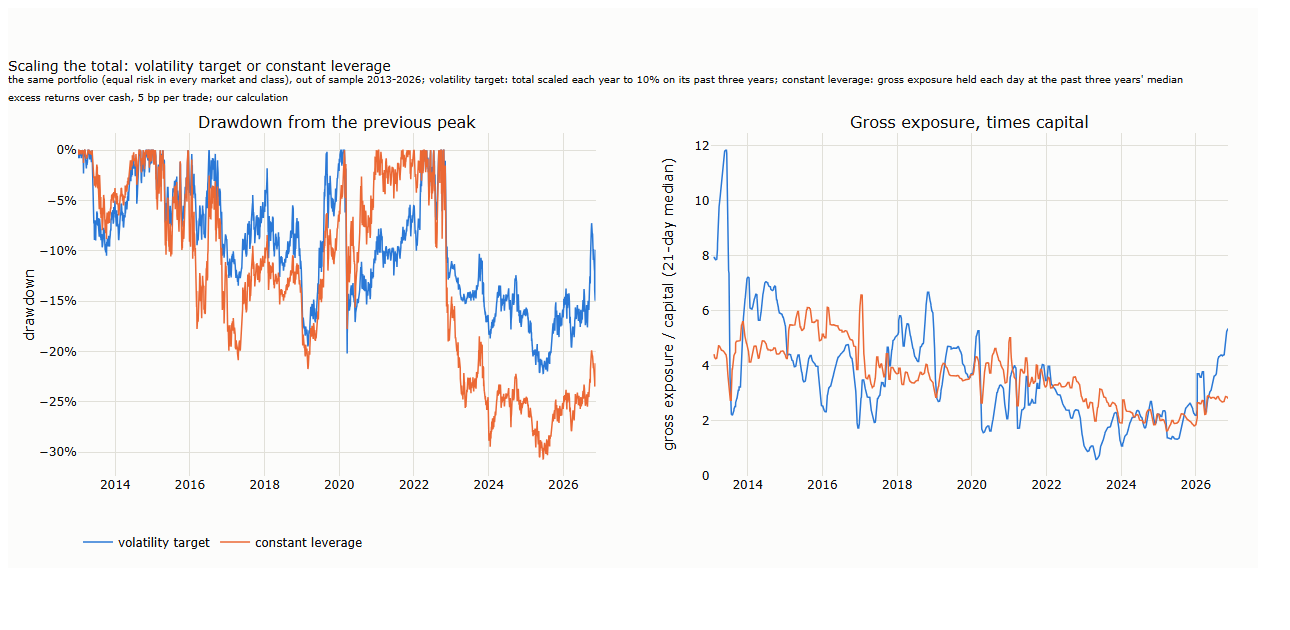

,volatility target,constant leverage
sharpe,0.486,0.390
return_a_year,0.052,0.048
vol,0.107,0.124
vol_3m_low,0.057,0.057
vol_3m_high,0.156,0.229
worst_month,-0.097,-0.146
worst_drawdown,-0.222,-0.307
gross_median,3.380,3.596
gross_low,1.321,1.951
gross_high,6.912,5.579


Sharpe difference, constant leverage minus volatility target: {'diff': np.float64(-0.096), 'ci90': array([-0.25,  0.06])}
scaled daily on today's positions: Sharpe 0.46, volatility 16.2%; 2023: -15.6% against -6.3% for the baseline


In [13]:
run("l27_charts.py")
pictures("27_total")
display(pd.DataFrame(L["profile"]).round(3))
print("Sharpe difference, constant leverage minus volatility target:", {k: np.round(v, 3) for k, v in L["sharpe_difference"].items()})
yr = lambda x, y: x.loc[str(y)].sum()
print(f"scaled daily on today's positions: Sharpe {L26.sharpe(D.vol_daily):.2f}, volatility {D.vol_daily.std() * np.sqrt(252):.1%}; 2023: {yr(D.vol_daily, 2023):+.1%} against {yr(D.rule, 2023):+.1%} for the baseline")

## 5. Taking profits

### 5.1 The rule by hand

SPY's EWMA crossover at 89 days with a take-profit at k = 4, written as a plain Python loop: the open gain since the signal last changed, in units of daily volatility at entry times the square root of the speed; flat above four units until the signal changes. Against the compiled `run` of `l27_takeprofit.py`.

In [14]:
import l27_takeprofit as TP
t, h, k = "SPY", 89, 4.0
c = close[t].dropna(); x = L26.excess(c, high[t].reindex(c.index), low[t].reindex(c.index), rf)[0]
r = x.pct_change().fillna(0).to_numpy(); vol = np.sqrt((x.pct_change() ** 2).ewm(span=L26.VOL_SPAN, min_periods=60).mean() * 252).to_numpy()
sig = L26.signals(x.to_frame("x"), x.to_frame("x"), x.to_frame("x"), h)["ewma"]["x"].to_numpy().astype(float)
pos, prev, gain, unit, flat, out, exits = 0.0, 0.0, 0.0, np.nan, False, np.zeros(len(r)), 0
for i in range(1, len(r)):
    out[i] = pos * r[i]; s = 0.0 if (np.isnan(sig[i]) or np.isnan(vol[i])) else sig[i]
    if s != prev: flat, gain, unit, prev = False, 0.0, vol[i] / np.sqrt(252) * np.sqrt(h), s      # a new trade
    else:
        gain += s * r[i]
        if not flat and gain > k * unit: flat, exits = True, exits + 1                             # take the profit
    target = 0.0 if (flat or s == 0 or np.isnan(vol[i])) else s * 0.10 / vol[i]
    new = pos + 0.1 * (target - pos); out[i] -= 5e-4 * abs(new - pos); pos = new
lib = TP.run(sig, r, vol, float(h), k, False, L26.LAMBDA, L26.VOL_TARGET, L26.COST_BP / 1e4)
print(f"{exits} take-profits; largest daily difference from the library: {np.abs(out - lib).max():.1e}")

4 take-profits; largest daily difference from the library: 0.0e+00


### 5.2 Results

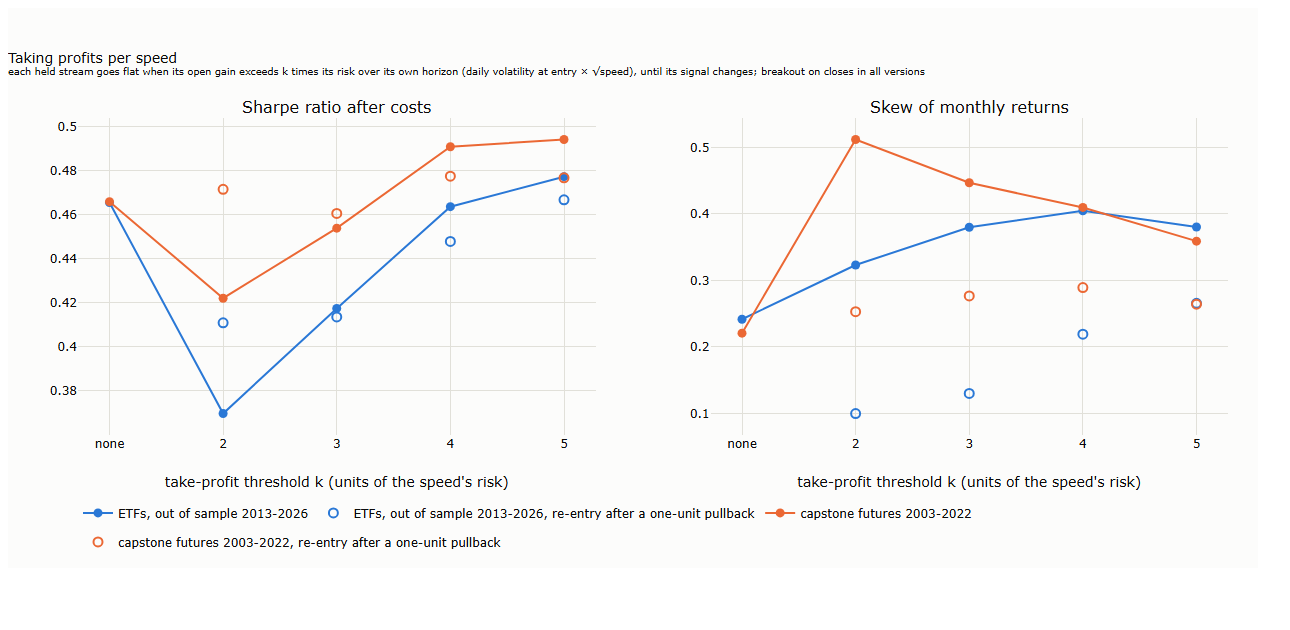

etf


,None,2.0,3.0,4.0,5.0,2r,3r,4r,5r
sharpe,0.465,0.370,0.417,0.464,0.477,0.411,0.414,0.448,0.467
vol,0.107,0.077,0.090,0.095,0.099,0.086,0.097,0.101,0.103
dd_over_vol,-2.119,-2.250,-2.057,-1.989,-2.000,-2.188,-2.182,-2.125,-2.135
worst12_over_vol,-6.273,-6.121,-6.169,-6.108,-6.152,-6.435,-6.440,-6.308,-6.261
skew_monthly,0.242,0.323,0.380,0.405,0.380,0.100,0.130,0.219,0.266


bands: {'4.0': (-0.002, [-0.092, 0.087]), '5.0': (0.012, [-0.056, 0.076]), '3.0': (-0.048, [-0.174, 0.073])}
futures


,None,2.0,3.0,4.0,5.0,2r,3r,4r,5r
sharpe,0.466,0.422,0.454,0.491,0.494,0.471,0.461,0.477,0.477
vol,0.109,0.079,0.092,0.098,0.103,0.087,0.099,0.103,0.106
dd_over_vol,-2.447,-3.211,-2.775,-2.518,-2.442,-2.925,-2.668,-2.501,-2.459
worst12_over_vol,-6.234,-5.053,-5.551,-5.762,-5.963,-5.701,-5.982,-6.063,-6.146
skew_monthly,0.221,0.512,0.447,0.410,0.359,0.253,0.277,0.289,0.264


bands: {'4.0': (0.025, [-0.036, 0.09]), '5.0': (0.028, [-0.011, 0.07]), '3.0': (-0.012, [-0.098, 0.076])}


In [15]:
pictures("27_takeprofit")
TPR = result("takeprofit.json")
for d in ("etf", "futures"):
    print(d); display(pd.DataFrame({k: {m: v[m] for m in ("sharpe", "vol", "dd_over_vol", "worst12_over_vol", "skew_monthly")} for k, v in TPR[d].items()}).round(3))
    print("bands:", {k: (round(v["diff"], 3), [round(b, 3) for b in v["ci90"]]) for k, v in TPR[d + "_bands"].items()})

## 6. Crises

### 6.1 Which speeds work in crises?

Each speed's return in each S&P 500 fall of more than 15%, and the share of the falls in which it beat the held set; a speed works in crises if it does so in two thirds of them on both datasets.

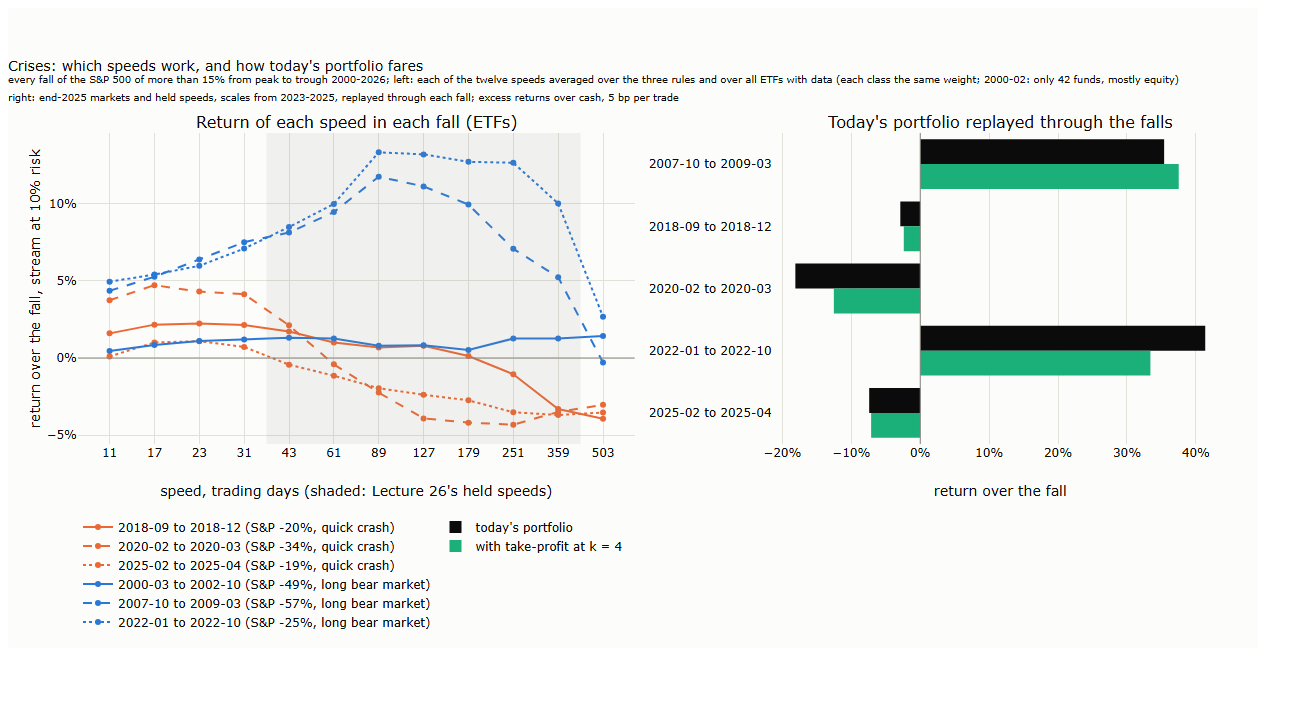

,11,17,23,31,43,61,89,127,179,251,359,503,held set
2000-03 (-49%),0.004,0.008,0.011,0.012,0.013,0.013,0.008,0.008,0.005,0.013,0.013,0.014,0.010
2007-10 (-57%),0.043,0.053,0.064,0.075,0.081,0.094,0.117,0.111,0.099,0.071,0.052,-0.003,0.085
2018-09 (-20%),0.016,0.022,0.022,0.021,0.017,0.010,0.007,0.008,0.001,-0.011,-0.033,-0.039,-0.002
2020-02 (-34%),0.037,0.047,0.043,0.041,0.021,-0.004,-0.022,-0.039,-0.042,-0.043,-0.035,-0.030,-0.025
2022-01 (-25%),0.049,0.054,0.060,0.071,0.085,0.100,0.133,0.132,0.127,0.126,0.100,0.027,0.109
2025-02 (-19%),0.001,0.010,0.011,0.007,-0.004,-0.011,-0.020,-0.024,-0.027,-0.035,-0.037,-0.035,-0.023


,11,17,23,31,43,61,89,127,179,251,359,503
etf,0.5,0.5,0.67,0.67,0.67,0.83,0.83,0.5,0.5,0.33,0.17,0.17
futures,0.4,0.4,0.40,0.40,0.60,0.60,0.60,0.4,0.6,0.60,0.40,0.20


speeds that work in crises: none


In [16]:
pictures("27_crisis")
CR = result("crisis.json")
display(pd.DataFrame({f"{e['peak'][:7]} ({e['spx_fall']:.0%})": e["etf"]["by_speed"] | {"held set": e["etf"]["held"]} for e in CR["episodes"] if e.get("etf")}).T.round(3))
display(pd.DataFrame(CR["beat_share"]).drop(columns=["etf_n", "futures_n"], errors="ignore").round(2).T)
print("speeds that work in crises:", CR["works"] or "none")

### 6.2 Today's portfolio in past crises

In [17]:
ST = result("stress.json")
pd.DataFrame({f"{e['peak'][:7]} to {e['trough'][:7]}": {"S&P 500": e["spx"], "markets": f"{e['plain']['markets']} of {e['plain']['of']}", "return": e["plain"]["ret"], "with take-profit 4": e["take-profit 4"]["ret"],
              "drawdown": e["plain"]["drawdown"], "worst day": e["plain"]["worst_day"]} | {f"class: {k}": v for k, v in e["plain"]["by_class"].items()} for e in ST["episodes"]}).T

,S&P 500,markets,return,with take-profit 4,drawdown,worst day,class: Equity,class: Rates,class: Credit,class: Commodities,class: FX
2000-03 to 2002-10,-0.491469,5 of 20,0.062996,0.063553,-0.060982,-0.017864,0.062996,NaN,NaN,NaN,NaN
2007-10 to 2009-03,-0.567754,19 of 20,0.353895,0.375085,-0.13142,-0.07203,0.059388,0.088761,0.026844,0.132766,0.046135
2018-09 to 2018-12,-0.197782,20 of 20,-0.028916,-0.023884,-0.070598,-0.03126,-0.024336,-0.02325,0.011762,-0.001947,0.008855
2020-02 to 2020-03,-0.33925,20 of 20,-0.181208,-0.125373,-0.235097,-0.07259,-0.084269,0.005131,-0.16361,0.079841,-0.018302
2022-01 to 2022-10,-0.254251,20 of 20,0.413541,0.333989,-0.106364,-0.038323,-0.036928,0.130784,0.098068,0.044039,0.177577
2025-02 to 2025-04,-0.189022,20 of 20,-0.074099,-0.071252,-0.074691,-0.013645,-0.008484,-0.013698,-0.028178,0.000517,-0.024256


## 7. Shipped against recomputed

With `RUN_ALL`, the rerun's key numbers against the shipped results. With the same download they match exactly; a later download can differ slightly, since Yahoo revises adjusted prices when funds pay distributions.

In [18]:
rows = [dict(number=f"Sharpe, {v}", shipped=result("portfolios.json", SHIPPED)["summary"][v]["sharpe"], recomputed=result("portfolios.json")["summary"][v]["sharpe"])
        for v in ("rule", "equal_capital", "constant_leverage", "ward")]
rows += [dict(number=f"speed blend, {v}", shipped=result("speeds.json", SHIPPED)["oos"][v], recomputed=result("speeds.json")["oos"][v]) for v in ("correlation", "max_sharpe")]
pd.DataFrame(rows).round(4)

,number,shipped,recomputed
0,"Sharpe, rule",0.4862,0.4862
1,"Sharpe, equal_capital",0.4418,0.4418
2,"Sharpe, constant_leverage",0.3901,0.3901
3,"Sharpe, ward",0.5219,0.5219
4,"speed blend, correlation",0.4816,0.4816
5,"speed blend, max_sharpe",0.4551,0.4551


**A test of your own.** Change one part of the baseline and judge it against the rest: the volatility target (`TARGET` in `scripts/l27.py`), the window of the scales (the `hist` slices), the take-profit grid (`KS` in `scripts/l27_takeprofit.py`), or the crisis threshold (`fall` in `scripts/l27_crisis.py`). Rerun with `RUN_ALL`. Any change made after looking at results should be dated in `results/hypotheses.md` before it is judged on later data, as every change of this lecture was.